# Variational Quantum Algorithms - Workshop

---




In this session we will cover:

1. What kinds of problems Variational Quantum Algorithms are built for.
2. Analyse and motivate each part of the algorithm.
3. Run a single qubit VQA, and compare to a known solution.
4. **Bonus, for home:** uses the same method to find the lowest energy of a hydrogen molecule (Sections 6–9).


In [ ]:
%pip install -q qiskit==2.5.2 scipy matplotlib pylatexenc # installs the necessary packages we will be using in this notebook

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorSampler, StatevectorEstimator

BLUE, RED, GREEN, GREY = "#1f77b4", "#d62728", "#2ca02c", "#9a9a9a"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})
# this cell imports the specific funtions and classes. It also sets some fomat paramters of the notebook

## 1. The problem: finding the smallest value

A surprising number of questions in science and industry come down to the same task: **find the settings that make some quantity as small as possible.** This is called an optimisation problem.

| Field | A real example | What we want to make as small as possible | What we can adjust |
| :--- | :--- | :--- | :--- |
| **Logistics** | A courier like Takealot or DHL planning the day's route for one driver with 30 parcels | The total distance driven (which determines fuel cost and delivery time) | The order in which the stops are visited |
| **Machine learning** | A spam filter deciding which emails go to your junk folder | How often it gets emails wrong, measured by an error score called the loss | The internal settings (weights) of the model |
| **Chemistry** | Predicting how atoms bond to form a stable molecule like $\text{H}_2$ | The molecule's total energy | The arrangement (quantum state) of its electrons |

Variational quantum algorithms are one way to tackle problems like these with a quantum computer.

## 2. What is a variational quantum algorithm?

A variational quantum algorithm (VQA) has two parts that take turns:

- **A parameterised quantum circuit.** This runs on the quantum computer. Some of its gates have adjustable rotation angles, called **parameters** and written $\boldsymbol\theta$. The circuit prepares a quantum state, and then we measure it.
- **A classical optimiser.** This is an ordinary program on a classical computer. It looks at the **cost**, one number worked out from the measurement results, and chooses new parameter values to make it smaller.

Three words describe the method:

- **Variational:** the parameter values, and so the quantum state, are varied step by step.
- **Hybrid:** a quantum computer and a classical computer share the work.
- **Heuristic:** it is a search. It finds a low cost, but nothing guarantees it is the lowest possible.

### 2.1 The loop

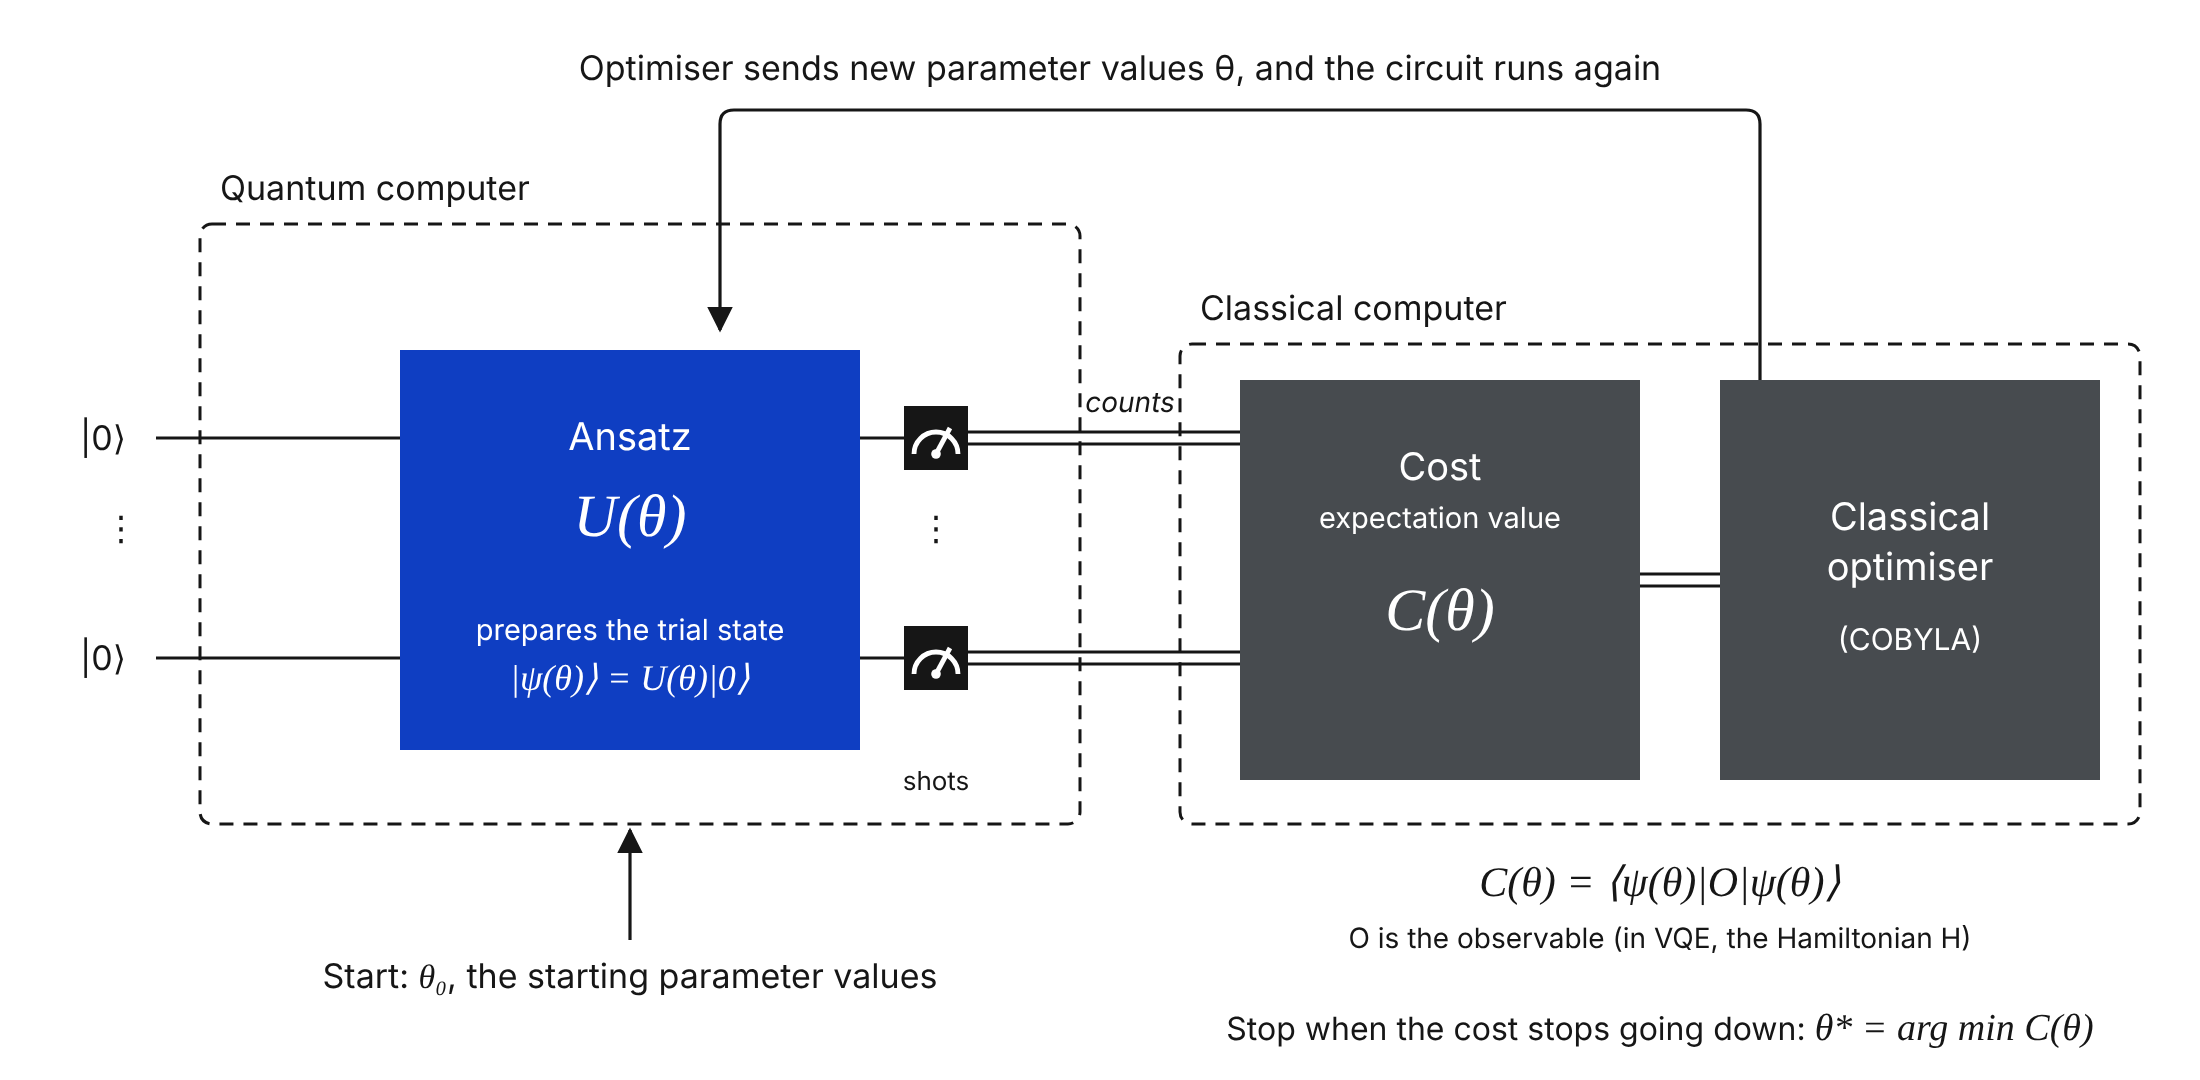

The quantum computer only runs and measures the circuit. Parameter improvements are made on the classical computer.

## 3. The building blocks

### 3.1 The four components

Every VQA is put together from the same four parts.

| Component | What it does |
|---|---|
| **Observable** | The quantity whose average we want to make as small as possible, written as a matrix $O$. It gives each measurement outcome a value. |
| **Ansatz** | The parameterised quantum circuit. Each choice of parameter values produces a different quantum state, called the **trial state**. $$\lvert\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)\,\lvert 0\rangle$$ |
| **Estimator** | Measures the trial state for many shots and averages the values the observable gives each outcome. That average estimates the **expectation value**, which is the **cost**: the number we minimise. |
| **Classical optimiser** | Looks at the cost and chooses new parameter values that should make it smaller. |

The quantum computer runs the ansatz and the measurements. Everything else is classical.

### 3.2 Ansatz and trial state

The **ansatz** is the design of the circuit: which gates go where, with the parameters left unassigned. The design stays fixed for the whole run; only the parameter values change.

The **trial state** is what you get when you fill in one set of parameter values and run the circuit. It is the algorithm's current guess.

Different parameter values give a different trial state:

$$\lvert\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)\,\lvert 0\rangle$$

For a single qubit, the most general parameterised gate in Qiskit is the $U2$ gate, with three angles $\theta$, $\phi$ and $\lambda$:

$$U(\theta, \phi, \lambda) = \begin{pmatrix} \cos\frac{\theta}{2} & -e^{i\lambda}\sin\frac{\theta}{2} \\[4pt] e^{i\phi}\sin\frac{\theta}{2} & e^{i(\phi+\lambda)}\cos\frac{\theta}{2} \end{pmatrix}$$

By choosing the three angles, it can produce any single-qubit gate (up to a global phase, which does not change any measurement). Setting $\phi = \lambda = 0$ gives the rotation $R_Y(\theta) = U(\theta, 0, 0)$, the gate we use in Section 5.


### 3.3 Observables: what each outcome is worth

Measuring a qubit only tells us which outcome happened, $0$ or $1$. To average results we need numbers, and that is what an **observable** gives us: a matrix that gives each outcome a value.

The simplest one is **Pauli-Z**:

$$Z = \begin{pmatrix} +1 & 0 \\ 0 & -1 \end{pmatrix}$$


Because $Z$ is already aligned with standard measurement basis, we can read its scores directly off the diagonal:


outcome $0$ is worth $+1$, and outcome $1$ is worth $-1$.


Other observables are not aligned with standard measurement basis, so we must rotate the qubit before measuring.

To measure **Pauli-X**, for example, we apply a Hadamard gate $H$ gate right before measuring. This rotates the **Pauli-X** basis into the standard measurement basis, allowing us to measure as usual and apply the same scoring rule:

\(0\) is worth \(+1\), and \(1\) is worth \(-1\).

### 3.4 Expectation value and cost function

The **expectation value** is the average value we would get from measuring an observable many times on the same state:

$$\langle O\rangle_\psi = \langle\psi\rvert\, O\, \lvert\psi\rangle$$

For $Z$ it is just the fraction of 0s minus the fraction of 1s. With $N$ **shots** (runs of the circuit), $N_0$ zeros and $N_1$ ones:

$$\langle Z\rangle \approx \frac{(+1)\,N_0 + (-1)\,N_1}{N} = \frac{N_0 - N_1}{N}$$

The **cost function** $C(\boldsymbol\theta)$ gives the **cost**, the number the classical optimiser tries to make as small as possible. In the simplest case, which is all we need today, it is the expectation value of the observable in the trial state:

$$C(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)\rvert\, O\, \lvert\psi(\boldsymbol\theta)\rangle$$

### 3.5 Shot noise

Every shot is random, so an expectation value from a finite number of shots is only an estimate. This error is called **shot noise**, and its typical size is the standard deviation $\sigma$:

$$\sigma \approx \sqrt{\frac{1 - \langle Z\rangle^2}{N}}$$

Notice the square root: four times as many shots only halves the error, so precise answers need a lot of shots.

### 3.6 Pauli strings

The three **Pauli matrices** are $X$, $Y$ and $Z$, plus the $I$ (identity). A **Pauli string** puts one of them on each qubit, for example $ZZ$ or $XX$. A quantum computer can measure any Pauli string: $Z$ and $I$ directly, and $X$ or $Y$ after a quick basis change (for $X$, a Hadamard gate first).

For a string like $ZZ$, each qubit gives its $+1$ or $-1$ and we multiply the two values. (Qiskit writes qubit 0 on the right.)

| Outcome | Qubit 1 | Qubit 0 | $ZZ$ value |
|---|---|---|---|
| 00 | $+1$ | $+1$ | $+1$ |
| 01 | $+1$ | $-1$ | $-1$ |
| 10 | $-1$ | $+1$ | $-1$ |
| 11 | $-1$ | $-1$ | $+1$ |

So $ZZ$ is $+1$ when the qubits agree and $-1$ when they differ.

The key fact is that **any observable can be written as a weighted sum of Pauli strings**, with real weights $c_j$. Because averages add up, its expectation value splits the same way:

$$O = \sum_j c_j P_j \quad\Longrightarrow\quad \langle O\rangle = \sum_j c_j\,\langle P_j\rangle$$

So we measure the expectation value of each string, multiply by its weight and add everything up.

## 4. Why use a quantum computer, and why keep the circuit short?

### 4.1 The quantum computer's one job

The quantum computer has one job: prepare the trial state and measure it, so that we can estimate the expectation value.

A classical computer can calculate the expectation value too, but it has to store the quantum state as a list of numbers, and that list doubles in length with every qubit we add:

| Qubits | Numbers needed to store the state |
|---|---|
| 2 | 4 |
| 10 | about 1 000 |
| 30 | about 1 billion |
| 50 | about $10^{15}$ |

A quantum computer does not store this list. It prepares the state on real qubits and measures it. How much work that takes depends on the circuit and on how precise we need the answer to be, not on the length of the list.

This is a trade, not a guaranteed win: no pracrical speed-up has been proven for VQAs.

### 4.2 Short circuits

A circuit is **short** when it has only a few layers of gates (a small **circuit depth**). On today's hardware every gate has a small chance of going wrong, and those chances multiply. If each gate has a fidelity of 99% (it works correctly 99% of the time) and the gates fail independently, a circuit with 100 gates runs without any error only about 37% of the time:

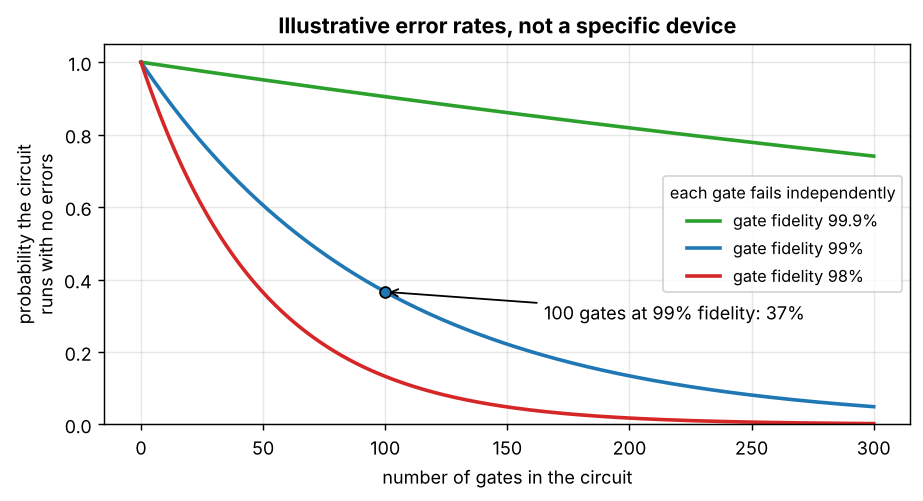

That is why a VQA runs only a short circuit on the quantum computer and leaves the many rounds of improvement to the classical optimiser.

### 4.3 The goal in one line

Everything so far fits in one line:

$$\boldsymbol\theta^* = \arg\min_{\boldsymbol\theta}\; C(\boldsymbol\theta)$$

$\boldsymbol\theta^*$ are the best parameter values, the ones the classical optimiser is looking for. "$\arg\min$" means "the value of $\boldsymbol\theta$ that makes what follows as small as possible", and $C(\boldsymbol\theta)$ is the cost. Now let's watch the loop run.

## 5. A first example: one qubit, one parameter

### 5.1 The setup

| Component | In this example |
|---|---|
| Observable | $Z$ (outcome 0 is worth $+1$, outcome 1 is worth $-1$) |
| Ansatz | one rotation gate $R_Y(\theta)$ with one parameter $\theta$ |
| Estimator | 1000 shots, then $\langle Z\rangle \approx (N_0 - N_1)/N$ |
| Classical optimiser | COBYLA |

The rotation gate $R_Y(\theta)$ is a $2\times2$ matrix:

$$R_Y(\theta) = \begin{pmatrix} \cos\frac{\theta}{2} & -\sin\frac{\theta}{2} \\[4pt] \sin\frac{\theta}{2} & \cos\frac{\theta}{2} \end{pmatrix}$$

**Step 1: build the trial state.** The qubit starts in $\lvert 0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$, so applying the gate picks out the first column:

$$\lvert\psi(\theta)\rangle = R_Y(\theta)\lvert 0\rangle = \begin{pmatrix} \cos\frac{\theta}{2} \\[4pt] \sin\frac{\theta}{2} \end{pmatrix} = \cos\tfrac{\theta}{2}\lvert 0\rangle + \sin\tfrac{\theta}{2}\lvert 1\rangle$$

**Step 2: find the probabilities.** The probability of each outcome is the absolute square of its amplitude (the Born rule):

$$P(0) = \big|\langle 0\vert\psi(\theta)\rangle\big|^2 = \left|\cos\tfrac{\theta}{2}\right|^2 = \cos^2\tfrac{\theta}{2}, \qquad P(1) = \big|\langle 1\vert\psi(\theta)\rangle\big|^2 = \left|\sin\tfrac{\theta}{2}\right|^2 = \sin^2\tfrac{\theta}{2}$$

The amplitudes here are real numbers, so the absolute square is just the ordinary square. The two probabilities add up to 1, because $\cos^2 x + \sin^2 x = 1$.

**Step 3: find the expectation value.** Outcome 0 is worth $+1$ and outcome 1 is worth $-1$, so

$$C(\theta) = \langle Z\rangle_\theta = (+1)\,P(0) + (-1)\,P(1) = \cos^2\tfrac{\theta}{2} - \sin^2\tfrac{\theta}{2} = \cos\theta$$

The last step uses the identity $\cos^2 x - \sin^2 x = \cos 2x$.

| $\theta$ | Trial state | $\langle Z\rangle$ |
|---|---|---|
| $0$ | $\lvert 0\rangle$ | $+1$ |
| $\pi/2$ | equal mix of $\lvert 0\rangle$ and $\lvert 1\rangle$ | $0$ |
| $\pi$ | $\lvert 1\rangle$ | $-1$ |

The lowest possible cost is $-1$, at $\theta = \pi$. We know the answer in advance, which lets us check that the method really finds it.

### 5.2 Build the circuit

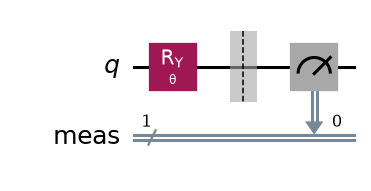

In [ ]:
theta = Parameter("θ")
qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()
qc.draw("mpl")

### 5.3 Measuring the cost

Each round of the loop, the quantum computer runs the circuit for 1000 shots, and the counts are turned into one number using $\langle Z\rangle \approx (N_0 - N_1)/N$.

Here the quantum computer is the **Sampler**, a simulator that runs in this session and returns counts, just like real hardware. `run_counts` runs the circuit and returns the counts, and `expectation_z` turns those counts into $\langle Z\rangle$. Here we try it once, at $\theta = \pi/2$.

In [ ]:
sampler = StatevectorSampler(seed=42)
shots = 1000

def run_counts(circuit, values):
    return sampler.run([(circuit, values)], shots=shots).result()[0].data.meas.get_counts()

def expectation_z(counts):
    return (counts.get("0", 0) - counts.get("1", 0)) / shots

counts = run_counts(qc, [np.pi / 2])
print("Counts at θ = π/2 :", counts)
print(f"⟨Z⟩ = ({counts.get('0', 0)} − {counts.get('1', 0)}) / {shots} = {expectation_z(counts):+.3f}")
print(f"Exact value cos(π/2) = {np.cos(np.pi / 2):+.3f}")

Counts at θ = π/2 : {'1': 497, '0': 503}
⟨Z⟩ = (503 − 497) / 1000 = +0.006
Exact value cos(π/2) = +0.000


We get $+0.006$ instead of exactly $0$. That small gap is shot noise, and it sits well inside $\sigma \approx 0.032$ from Section 3.5. This single number, the cost, is all the classical optimiser sees each round.

### 5.4 Letting an optimiser search

With one parameter we could simply try every value. With many parameters that falls apart fast: $p$ parameters with $m$ values each needs $m^p$ evaluations.

| Parameters $p$ | Evaluations needed with $m = 10$ |
|---|---|
| 1 | 10 |
| 4 | 10 000 |
| 100 | $10^{100}$, more than the number of atoms in the observable universe |

So instead a classical optimiser searches. We use **COBYLA** (Constrained Optimisation BY Linear Approximation), which works like this:

- it only uses cost values, never slopes, so it is **gradient-free**;
- it fits a simple straight-line model to the points it has tried;
- it steps towards a lower cost, but never further than a distance it trusts (its **trust region**);
- it shrinks that distance as it closes in, and stops once it is tiny.

The `cost` function connects the two computers: it takes a parameter value from the optimiser, runs and measures the circuit, and returns the cost, $\langle Z\rangle$. Each call is one **evaluation**. COBYLA starts at $\theta = 0.5$.

In [ ]:
fine = np.linspace(0, 2 * np.pi, 400)
ticks = ([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi], ["0", "π/2", "π", "3π/2", "2π"])
history = []

def cost(params):
    value = expectation_z(run_counts(qc, params))
    history.append((params[0], value))
    return value

theta_start = [0.5]
result = minimize(cost, theta_start, method="COBYLA", options={"maxiter": 60})

print(f"Starting parameter : θ = {theta_start[0]:.2f}")
print(f"Best parameter     : θ* = {result.x[0]:.3f}   (exact answer π ~ {np.pi:.3f})")
print(f"Minimum ⟨Z⟩ found  : {result.fun:+.3f}   (exact minimum −1)")
print(f"Evaluations        : {result.nfev}")

Starting parameter : θ = 0.50
Best parameter     : θ* = 3.100   (exact answer π ~ 3.142)
Minimum ⟨Z⟩ found  : -1.000   (exact minimum −1)
Evaluations        : 12


### 5.5 Reading the search

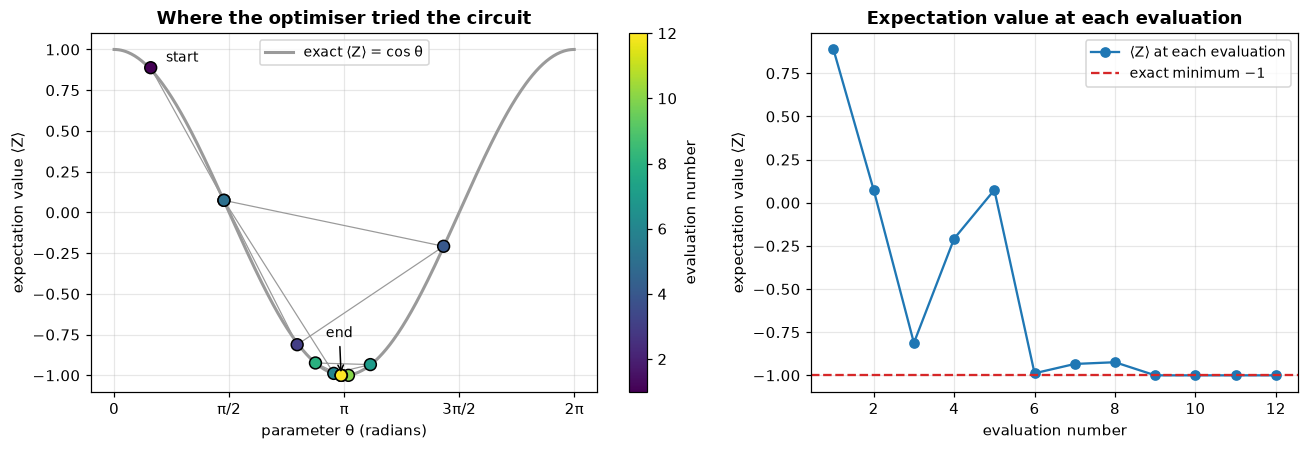

In [ ]:
th, ev = np.array(history).T
steps = np.arange(1, len(history) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.plot(fine, np.cos(fine), color=GREY, lw=2, label="exact ⟨Z⟩ = cos θ")
ax1.plot(th, ev, "-", color=GREY, lw=0.8)
pts = ax1.scatter(th, ev, c=steps, cmap="viridis", s=60, edgecolor="black", zorder=3)
ax1.annotate("start", (th[0], ev[0]), xytext=(10, 4), textcoords="offset points", fontsize=9)
ax1.annotate("end", (th[-1], ev[-1]), xytext=(-10, 25), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->"))
fig.colorbar(pts, ax=ax1, label="evaluation number")
ax1.set_xticks(*ticks)
ax1.set_xlabel("parameter θ (radians)")
ax1.set_ylabel("expectation value ⟨Z⟩")
ax1.set_title("Where the optimiser tried the circuit")
ax1.legend(loc="upper center", fontsize=9)

ax2.plot(steps, ev, "o-", color=BLUE, label="⟨Z⟩ at each evaluation")
ax2.axhline(-1, color=RED, ls="--", label="exact minimum −1")
ax2.set_xlabel("evaluation number")
ax2.set_ylabel("expectation value ⟨Z⟩")
ax2.set_title("Expectation value at each evaluation")
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

- The optimiser starts with big exploratory steps, overshoots to $\theta = 4.5$, then closes in with smaller and smaller steps. It first reaches a cost of $-1$ at evaluation 9 ($\theta = 3.1$) and stops after 12 evaluations, without ever seeing the formula $\cos\theta$. It only ever receives cost values.
- It stops at $3.10$ rather than exactly $\pi$. With 1000 shots, every value of $\theta$ that close to $\pi$ almost always gives all 1s, so the optimiser has no way to tell them apart.

That is a complete variational quantum algorithm: a quantum circuit prepares and measures the trial state, and a classical optimiser uses the cost to choose better parameters until the cost stops going down.


## 6. From VQA to VQE

### 6.1 What VQE is

The **Variational Quantum Eigensolver (VQE)** is a specific type of VQA we get when the observable is a **Hamiltonian** $H$—the matrix that describes a physical system's total energy.

| Component | General VQA (Sections 2–5) | VQE (Chemistry & Physics) |
| :--- | :--- | :--- |
| **Observable** | Any cost operator $O$ | System Hamiltonian $H$ |
| **Cost function** | $C(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)\rvert\, O\, \lvert\psi(\boldsymbol\theta)\rangle$ | Energy $E(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)\rvert\, H\, \lvert\psi(\boldsymbol\theta)\rangle$ |
| **Optimisation loop** | Quantum circuit + classical optimiser | **Identical** hybrid loop |
| **Goal** | Minimise an abstract cost | Find the lowest allowed energy ($E_0$) |

The hybrid quantum–classical loop is identical to the one we just ran. What changes is the physical interpretation: finding the lowest energy a molecule or material can have turns out to be an **eigenvalue problem**.

---

### 6.2 Eigenvalues and eigenvectors

Think of a guitar string: when plucked, it can only vibrate at specific resonant frequencies (its fundamental note and overtones), while any arbitrary vibration is just a blend of those pure frequencies. A Hamiltonian works the same way for a quantum system.

When a matrix acts on a quantum state, it usually rotates or changes it into a different state. A few special states are left pointing in the exact same direction and are only multiplied by a number:

$$H\,\lvert\psi_k\rangle = E_k\,\lvert\psi_k\rangle$$

- Each special state $\lvert\psi_k\rangle$ is an **eigenvector** (a pure, stationary energy state).
- The number $E_k$ is its **eigenvalue**. For a Hamiltonian, the eigenvalues are the **only energies the system is allowed to have**.
- The smallest eigenvalue $E_0$ is the **ground-state energy**, and its eigenvector $\lvert\psi_0\rangle$ is the **ground state**. That is what VQE is hunting for.

**A quick 1-qubit check ($H = Z$):**
$$Z\lvert 0\rangle = +1\cdot\lvert 0\rangle \qquad \text{and} \qquad Z\lvert 1\rangle = -1\cdot\lvert 1\rangle$$
Because $Z$ leaves $\lvert 0\rangle$ and $\lvert 1\rangle$ unchanged up to a scalar factor, they are its eigenvectors, and its allowed energies (eigenvalues) are $+1$ and $-1$.

> **Why energies are always real numbers:** Every physical Hamiltonian is **Hermitian**, meaning it equals its own conjugate transpose ($H = H^\dagger$). A core theorem of linear algebra guarantees that all eigenvalues of a Hermitian matrix are real numbers—never complex.

---

### 6.3 The variational principle

Why are we guaranteed that minimising $E(\boldsymbol\theta)$ pushes our circuit toward the true ground state instead of getting tricked? Because of the **variational principle**:

1. **Superposition decomposition:** Any trial state $\lvert\psi\rangle$ can be written as a mix of the Hamiltonian's eigenvectors, $\lvert\psi\rangle = \sum_k c_k\lvert\psi_k\rangle$, with probability weights $\vert{}c_k\vert{}^2$ that add up to $1$.
2. **Weighted average:** Its expected energy is simply the weighted average of those allowed energies:
   $$\langle\psi\rvert H\lvert\psi\rangle = \sum_k \vert{}c_k\vert{}^2 E_k$$
3. **Hard mathematical floor:** An average can never be smaller than the smallest value being averaged:

$$\langle\psi\rvert H\lvert\psi\rangle = \sum_k \vert{}c_k\vert{}^2 E_k \;\ge\; E_0$$


PNG bytes: 9410, Base64 length: 12548


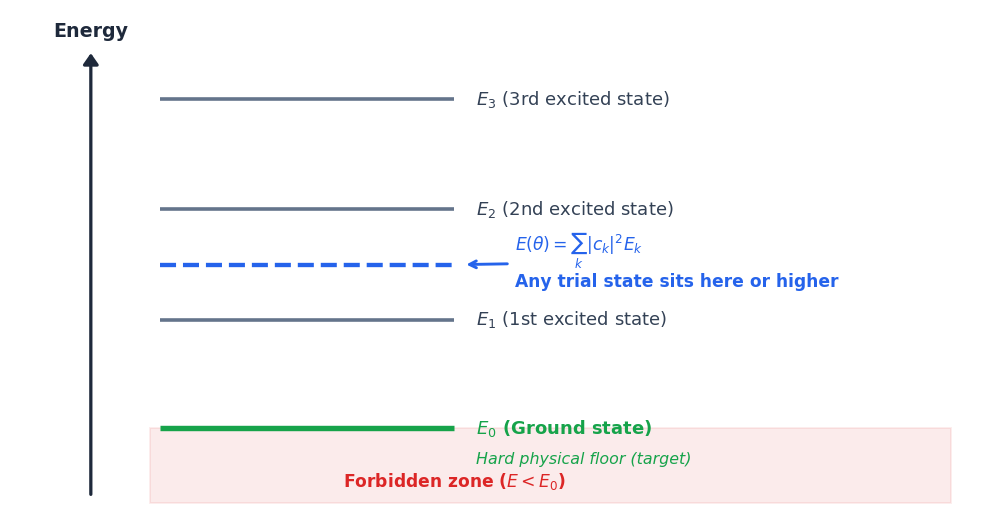

In [ ]:
import base64
import io
import matplotlib.pyplot as plt
from PIL import Image

# Workshop palette
BLUE = "#2563EB"
RED = "#DC2626"
GREEN = "#16A34A"
GREY = "#64748B"

fig, ax = plt.subplots(figsize=(7.6, 3.9), dpi=130)
fig.patch.set_facecolor("white")

# Energy levels matching the diagram
levels = [
    (-1.14, r"$E_0$ (Ground state)", GREEN, 3.0),
    (-0.55, r"$E_1$ (1st excited state)", GREY, 2.0),
    (0.05,  r"$E_2$ (2nd excited state)", GREY, 2.0),
    (0.65,  r"$E_3$ (3rd excited state)", GREY, 2.0),
]

x_left, x_right = 0.22, 0.56

for idx, (y, label, color, lw) in enumerate(levels):
    ax.hlines(y, x_left, x_right, colors=color, linewidth=lw, zorder=3)
    ax.text(x_right + 0.025, y, label, va="center", ha="left", fontsize=10,
            fontweight="bold" if idx == 0 else "normal",
            color=GREEN if idx == 0 else "#334155")

# Ground state annotation
ax.text(x_right + 0.025, -1.27, "Hard physical floor (target)",
        va="top", ha="left", fontsize=8.8, style="italic", color=GREEN)

# Forbidden zone below E0
ax.axhspan(-1.55, -1.14, xmin=0.14, xmax=0.96, color=RED, alpha=0.09, zorder=1)
ax.text(0.56, -1.43, r"Forbidden zone ($E < E_0$)",
        va="center", ha="center", fontsize=9.5, fontweight="bold", color=RED)

# Trial state energy line
y_trial = -0.25
ax.hlines(y_trial, x_left, x_right, colors=BLUE, linestyles="--", linewidth=2.4, zorder=4)
ax.annotate(
    r"$E(\theta) = \sum_k |c_k|^2 E_k$" + "\nAny trial state sits here or higher",
    xy=(x_right + 0.01, y_trial),
    xytext=(x_right + 0.07, y_trial + 0.02),
    va="center", ha="left", fontsize=9.5, fontweight="bold", color=BLUE,
    arrowprops=dict(arrowstyle="->", color=BLUE, lw=1.6, connectionstyle="arc3,rad=0.0")
)

# Energy axis arrow on the left
ax.annotate(
    "", xy=(0.14, 0.92), xytext=(0.14, -1.52),
    arrowprops=dict(arrowstyle="-|>,head_width=0.35,head_length=0.5", color="#1E293B", lw=1.8)
)
ax.text(0.14, 0.97, "Energy", ha="center", va="bottom", fontsize=10.5, fontweight="bold", color="#1E293B")

ax.set_xlim(0.05, 1.18)
ax.set_ylim(-1.58, 1.12)
ax.axis("off")

plt.tight_layout(pad=0.3)

# Save to PNG and quantize slightly with PIL for super-compact base64
buf = io.BytesIO()
fig.savefig(buf, format="png", bbox_inches="tight", pad_inches=0.08)
buf.seek(0)
img = Image.open(buf).convert("P", palette=Image.ADAPTIVE, colors=64)
out = io.BytesIO()
img.save(out, format="PNG", optimize=True)
png_bytes = out.getvalue()
b64 = base64.b64encode(png_bytes).decode("ascii")

fig.savefig("variational_principle_preview.png", bbox_inches="tight", pad_inches=0.08)
print(f"PNG bytes: {len(png_bytes)}, Base64 length: {len(b64)}")



No valid quantum state can ever go below the ground-state energy $E_0$, so **a lower energy always means a better approximation**.

> **Note on measurement noise:** This bound holds strictly for the *exact* expectation value (such as a statevector simulation). When estimating energy on real hardware or a shot-based simulator from a finite number of measurement shots, random statistical fluctuations can occasionally push an individual estimate slightly below $E_0$.

---

### 6.4 The VQE problem

Putting everything together, VQE turns quantum chemistry and physics into a constrained search over circuit parameters $\boldsymbol\theta$:

$$E_{\text{VQE}} = \min_{\boldsymbol\theta}\; \langle\psi(\boldsymbol\theta)\rvert H\lvert\psi(\boldsymbol\theta)\rangle \;\ge\; E_0$$

VQE estimates the smallest eigenvalue $E_0$ and prepares an approximation of the ground state $\lvert\psi_0\rangle$. It reaches $E_0$ **exactly** only when two conditions are met:

1. **Ansatz expressibility:** The parameterised circuit is flexible enough to actually prepare $\lvert\psi_0\rangle$ for some choice of angles.
2. **Classical optimisation:** The classical optimiser successfully navigates the parameter landscape to find those optimal angles without getting stuck.

**Connecting back to our 1-qubit VQA:** Looking back at our earlier example with $O = Z$, we were already running a miniature VQE with Hamiltonian $H = Z$. The minimum value the optimiser found, $-1$, is the smallest eigenvalue $E_0$ of $Z$, and the state the circuit prepared, $\lvert 1\rangle$, is its ground state $\lvert\psi_0\rangle$.

## 7. Bonus Section
### Why chemists care

Bond strengths and reaction energies come from differences between ground-state energies, and a molecule's shape is the arrangement of its atoms with the lowest ground-state energy. So that one number matters a great deal.

- Chemists need energies to within about $1.6\times10^{-3}$ Hartree (about 1 kcal/mol). This is called **chemical accuracy**. The **Hartree** (Ha) is the atomic unit of energy, the natural unit for atoms and molecules.
- Describing $n$ qubits exactly takes $2^n$ numbers. For 50 qubits that is about $10^{15}$.
- Classical computers can find the lowest eigenvalue of such matrices exactly up to roughly billions of rows, but not much more.

Approximate classical methods work well for many molecules, but not all. Those difficult cases are what motivate quantum approaches like VQE.

## 8. VQE for the hydrogen molecule

What we want to do:

1. **Find $E_0$:** use VQE to find the ground-state energy of H₂ to within chemical accuracy.
2. **Check it:** compare with the exact answer, which we can still compute classically for a molecule this small.
3. **Look at the state:** see which state VQE builds, and test whether the circuit needs entanglement.

### 8.1 The hydrogen Hamiltonian

$$H = c_0\,II + c_1\,IZ + c_2\,ZI + c_3\,ZZ + c_4\,XX$$

$$c_0 = -1.0524,\quad c_1 = 0.3979,\quad c_2 = -0.3979,\quad c_3 = -0.0113,\quad c_4 = 0.1809 \quad (\text{Hartree})$$

We did not choose these weights. They come from a classical chemistry calculation for H₂ at a bond length of 0.735 Å, which works out how strongly the electrons interact with the nuclei and with each other. Each weight turns the expectation value of one Pauli string, a number between $-1$ and $+1$, into energy in Hartree.

| Term | Weight (Ha) | What it measures |
|---|---|---|
| $II$ | $-1.0524$ | a constant shift, the same for every state |
| $IZ$ | $+0.3979$ | whether qubit 0 is 0 ($+1$) or 1 ($-1$) |
| $ZI$ | $-0.3979$ | whether qubit 1 is 0 ($+1$) or 1 ($-1$) |
| $ZZ$ | $-0.0113$ | whether the two qubits agree ($+1$) or differ ($-1$) |
| $XX$ | $+0.1809$ | flips both qubits, linking 01 with 10; this is where the entanglement comes from |

In [ ]:
H2 = SparsePauliOp.from_list([
    ("II", -1.052373245772859),
    ("IZ", 0.39793742484318045),
    ("ZI", -0.39793742484318045),
    ("ZZ", -0.01128010425623538),
    ("XX", 0.18093119978423156),
])
matrix = H2.to_matrix()

print("H as a sum of Pauli strings:")
for label, c in zip(H2.paulis.to_labels(), H2.coeffs.real):
    print(f"   {c:+.4f} × {label}")
print("\nH as a 4 × 4 matrix (rows and columns in the order 00, 01, 10, 11):")
print(np.round(matrix.real, 4))
print("\nIs H equal to its conjugate transpose (Hermitian)?", np.allclose(matrix, matrix.conj().T))

H as a sum of Pauli strings:
   -1.0524 × II
   +0.3979 × IZ
   -0.3979 × ZI
   -0.0113 × ZZ
   +0.1809 × XX

H as a 4 × 4 matrix (rows and columns in the order 00, 01, 10, 11):
[[-1.0637  0.      0.      0.1809]
 [ 0.     -1.837   0.1809  0.    ]
 [ 0.      0.1809 -0.2452  0.    ]
 [ 0.1809  0.      0.     -1.0637]]

Is H equal to its conjugate transpose (Hermitian)? True


### 8.2 Build the ansatz

$$\lvert\psi(\boldsymbol\theta)\rangle = \big[R_Y(\theta_2)\otimes R_Y(\theta_3)\big]\;\text{CNOT}_{0\to1}\;\big[R_Y(\theta_0)\otimes R_Y(\theta_1)\big]\;\lvert 00\rangle$$

There are four parameters. The CNOT is the gate that lets the two qubits become entangled.

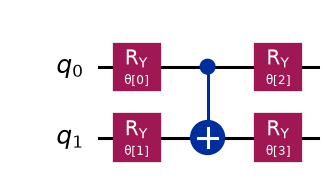

In [ ]:
params = ParameterVector("θ", 4)
ansatz = QuantumCircuit(2)
ansatz.ry(params[0], 0)
ansatz.ry(params[1], 1)
ansatz.cx(0, 1)
ansatz.ry(params[2], 0)
ansatz.ry(params[3], 1)
ansatz.draw("mpl")

### 8.3 Measuring the energy

The energy splits into the expectation values of the five Pauli strings:

$$E(\boldsymbol\theta) = c_0\langle II\rangle + c_1\langle IZ\rangle + c_2\langle ZI\rangle + c_3\langle ZZ\rangle + c_4\langle XX\rangle$$

$\langle II\rangle$ is always $1$. $IZ$, $ZI$ and $ZZ$ only use $I$ and $Z$, so they all come from the same shots, while $XX$ needs separate shots with a Hadamard gate on each qubit first. So H₂ needs only **two measurement settings**.

The cell below does this by hand from counts, with all four parameters set to $0$ (the state $\lvert 00\rangle$). It then compares the result with the **Estimator**, which returns the expectation value directly. In a simulator it calculates it exactly, with no shot noise. For $\lvert 00\rangle$ we expect $\langle IZ\rangle = \langle ZI\rangle = \langle ZZ\rangle = 1$ and $\langle XX\rangle = 0$, so

$$E = -1.0524 + 0.3979 - 0.3979 - 0.0113 + 0 = -1.0637 \text{ Ha}$$

In [ ]:
zeros = [0, 0, 0, 0]
labels = H2.paulis.to_labels()
coeffs = H2.coeffs.real

z_circuit = ansatz.assign_parameters(zeros)
z_circuit.measure_all()
x_circuit = ansatz.assign_parameters(zeros)
x_circuit.h([0, 1])
x_circuit.measure_all()
z_counts = sampler.run([z_circuit], shots=shots).result()[0].data.meas.get_counts()
x_counts = sampler.run([x_circuit], shots=shots).result()[0].data.meas.get_counts()

def pauli_average(counts, label):
    total = 0
    for bits, n in counts.items():
        sign = 1
        for letter, bit in zip(label, bits):
            if letter != "I" and bit == "1":
                sign = -sign
        total += sign * n
    return total / shots

measured_terms = [pauli_average(x_counts if "X" in l else z_counts, l) for l in labels]

estimator = StatevectorEstimator()

def energy(circuit, values):
    return float(estimator.run([(circuit, H2, values)]).result()[0].data.evs)

exact_terms = estimator.run([(ansatz, [SparsePauliOp(l) for l in labels], zeros)]).result()[0].data.evs

print("Z-basis counts:", dict(sorted(z_counts.items())))
print("X-basis counts:", dict(sorted(x_counts.items())))
print()
print(f"{'term':>4} | {'c_j':>8} | {'measured ⟨P_j⟩':>15} | {'exact ⟨P_j⟩':>11}")
print("-" * 48)
for l, c, m, e in zip(labels, coeffs, measured_terms, exact_terms):
    print(f"{l:>4} | {c:>+8.4f} | {m:>+15.3f} | {e:>+11.3f}")
print("-" * 48)
print(f"Energy from measurements : {np.dot(coeffs, measured_terms):+.4f} Ha")
print(f"Energy from Estimator    : {energy(ansatz, zeros):+.4f} Ha")

Z-basis counts: {'00': 1000}
X-basis counts: {'00': 263, '01': 240, '10': 240, '11': 257}

term |      c_j |  measured ⟨P_j⟩ | exact ⟨P_j⟩
------------------------------------------------
  II |  -1.0524 |          +1.000 |      +1.000
  IZ |  +0.3979 |          +1.000 |      +1.000
  ZI |  -0.3979 |          +1.000 |      +1.000
  ZZ |  -0.0113 |          +1.000 |      +1.000
  XX |  +0.1809 |          +0.040 |      +0.000
------------------------------------------------
Energy from measurements : -1.0564 Ha
Energy from Estimator    : -1.0637 Ha


$\langle XX\rangle$ comes out as $+0.040$ rather than $0$, which is shot noise again. From here on we use the Estimator, so shot noise does not affect the search.

### 8.4 Running VQE

In [ ]:
energy_history = []

def cost_h2(values):
    e = energy(ansatz, values)
    energy_history.append(e)
    return e

start = np.random.default_rng(seed=7).uniform(0, 2 * np.pi, 4)
result_h2 = minimize(cost_h2, start, method="COBYLA", options={"maxiter": 200})

print(f"VQE energy           : {result_h2.fun:.6f} Ha")
print(f"Evaluations          : {result_h2.nfev}")

VQE energy           : -1.857275 Ha
Evaluations          : 105


### 8.5 Checking against the exact answer

In a real problem we would not know the exact answer; that is the whole reason for running VQE. H₂ is small enough to solve exactly on a laptop, so here we can check.

Allowed energies (Hartree): [-1.8573 -1.2446 -0.8827 -0.2249]
Ground-state energy E₀ = -1.857275 Ha
Ground state = +0.994 |01⟩  -0.112 |10⟩
VQE energy             = -1.857275 Ha
Difference             = 1.2e-09 Ha   (chemical accuracy: 1.6e-03 Ha)


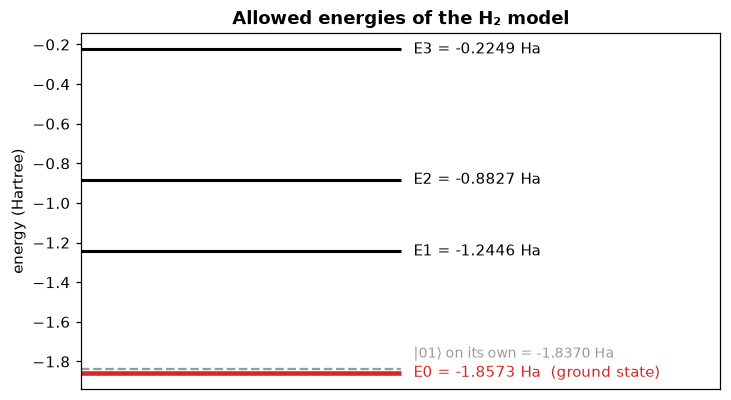

In [ ]:
eigenvalues, eigenvectors = np.linalg.eigh(matrix)
E0 = eigenvalues[0]
ground_state = eigenvectors[:, 0].real
ground_state *= np.sign(ground_state[np.argmax(np.abs(ground_state))])
hf_energy = matrix[1, 1].real
basis = ["|00⟩", "|01⟩", "|10⟩", "|11⟩"]

print("Allowed energies (Hartree):", np.round(eigenvalues, 4))
print(f"Ground-state energy E₀ = {E0:.6f} Ha")
print("Ground state = " + "  ".join(f"{a:+.3f} {b}" for a, b in zip(ground_state, basis) if abs(a) > 1e-6))
print(f"VQE energy             = {result_h2.fun:.6f} Ha")
print(f"Difference             = {result_h2.fun - E0:.1e} Ha   (chemical accuracy: 1.6e-03 Ha)")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, E in enumerate(eigenvalues):
    ax.hlines(E, 0, 1, color=RED if k == 0 else "black", lw=3 if k == 0 else 2)
    ax.text(1.04, E, f"E{k} = {E:.4f} Ha" + ("  (ground state)" if k == 0 else ""), va="center", color=RED if k == 0 else "black")
ax.hlines(hf_energy, 0, 1, color=GREY, ls="--", lw=1.5)
ax.text(1.04, hf_energy + 0.04, f"|01⟩ on its own = {hf_energy:.4f} Ha", va="bottom", color=GREY, fontsize=9)
ax.set_xlim(0, 2)
ax.set_xticks([])
ax.set_ylabel("energy (Hartree)")
ax.set_title("Allowed energies of the H₂ model")
ax.grid(False)
plt.show()

- All four energies are real, as expected for a Hermitian matrix. The smallest, the ground-state energy, is $E_0 = -1.8573$ Ha, and VQE matches it to within $10^{-9}$ Ha.
- The exact ground state is $\lvert\psi_0\rangle \approx 0.994\lvert 01\rangle - 0.112\lvert 10\rangle$: about 98.8% $\lvert 01\rangle$ and 1.2% $\lvert 10\rangle$.
- Its energy sits below that of $\lvert 01\rangle$ on its own (the dashed line), because the $XX$ term mixes in a little $\lvert 10\rangle$.

### 8.6 Reading the search

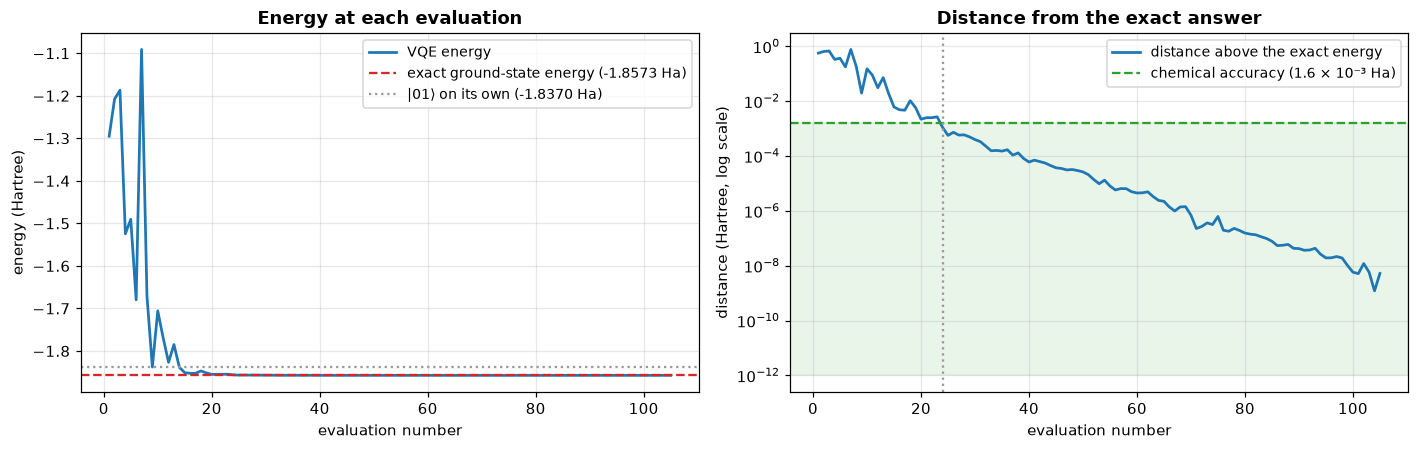

First evaluation within chemical accuracy: number 24


In [ ]:
E_hist = np.array(energy_history)
it = np.arange(1, len(E_hist) + 1)
first_ok = int(np.argmax(E_hist - E0 < 1.6e-3)) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(it, E_hist, color=BLUE, lw=1.8, label="VQE energy")
ax1.axhline(E0, color=RED, ls="--", label=f"exact ground-state energy ({E0:.4f} Ha)")
ax1.axhline(hf_energy, color=GREY, ls=":", label=f"|01⟩ on its own ({hf_energy:.4f} Ha)")
ax1.set_xlabel("evaluation number")
ax1.set_ylabel("energy (Hartree)")
ax1.set_title("Energy at each evaluation")
ax1.legend(fontsize=9)

ax2.semilogy(it, np.maximum(E_hist - E0, 1e-12), color=BLUE, lw=1.8, label="distance above the exact energy")
ax2.axhline(1.6e-3, color=GREEN, ls="--", label="chemical accuracy (1.6 × 10⁻³ Ha)")
ax2.axhspan(1e-12, 1.6e-3, color=GREEN, alpha=0.1)
ax2.axvline(first_ok, color=GREY, ls=":")
ax2.set_xlabel("evaluation number")
ax2.set_ylabel("distance (Hartree, log scale)")
ax2.set_title("Distance from the exact answer")
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"First evaluation within chemical accuracy: number {first_ok}")

- The energy settles onto the exact value and never goes below it, just as the variational principle promises.
- It reaches chemical accuracy at evaluation 24 and finishes about $10^{-9}$ Ha from the exact answer.

### 8.7 Which state did VQE prepare?

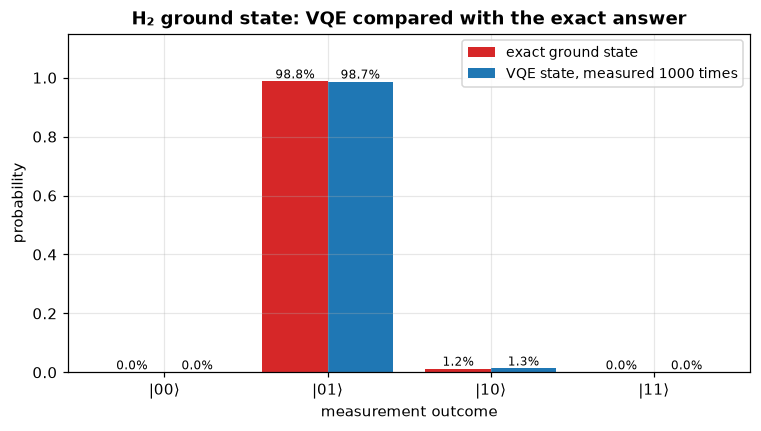

Overlap (fidelity) between the VQE state and the exact ground state: 1.0


In [ ]:
final_circuit = ansatz.assign_parameters(result_h2.x)
vqe_state = Statevector(final_circuit)
measured_final = final_circuit.copy()
measured_final.measure_all()
counts_h2 = sampler.run([measured_final], shots=shots).result()[0].data.meas.get_counts()

keys = ["00", "01", "10", "11"]
exact_probs = ground_state**2
vqe_probs = [counts_h2.get(k, 0) / shots for k in keys]
x = np.arange(4)

plt.figure(figsize=(8, 4))
b1 = plt.bar(x - 0.2, exact_probs, 0.4, color=RED, label="exact ground state")
b2 = plt.bar(x + 0.2, vqe_probs, 0.4, color=BLUE, label=f"VQE state, measured {shots} times")
plt.bar_label(b1, labels=[f"{p:.1%}" for p in exact_probs], fontsize=8)
plt.bar_label(b2, labels=[f"{p:.1%}" for p in vqe_probs], fontsize=8)
plt.xticks(x, basis)
plt.ylim(0, 1.15)
plt.xlabel("measurement outcome")
plt.ylabel("probability")
plt.title("H₂ ground state: VQE compared with the exact answer")
plt.legend(fontsize=9)
plt.show()
print("Overlap (fidelity) between the VQE state and the exact ground state:", round(abs(np.vdot(ground_state, vqe_state.data))**2, 6))

- VQE prepared the exact ground state: 98.8% $\lvert 01\rangle$ and 1.2% $\lvert 10\rangle$, with a fidelity of 1.0.
- $\lvert 01\rangle$ on its own is the simple textbook picture, with both electrons in the bonding orbital. Chemists call it the **Hartree–Fock state**, and its energy is $-1.8370$ Ha. Mixing in a little $\lvert 10\rangle$ lowers the energy by $0.0203$ Ha. This difference is called the **correlation energy**.
- A mix of $\lvert 01\rangle$ and $\lvert 10\rangle$ cannot be split into a separate state for each qubit, so the ground state is entangled.

### 8.8 Removing the entangling gate

With CNOT    : -1.8573 Ha   distance above exact 0.0000 Ha
Without CNOT : -1.8370 Ha   distance above exact 0.0203 Ha  (13 × chemical accuracy)


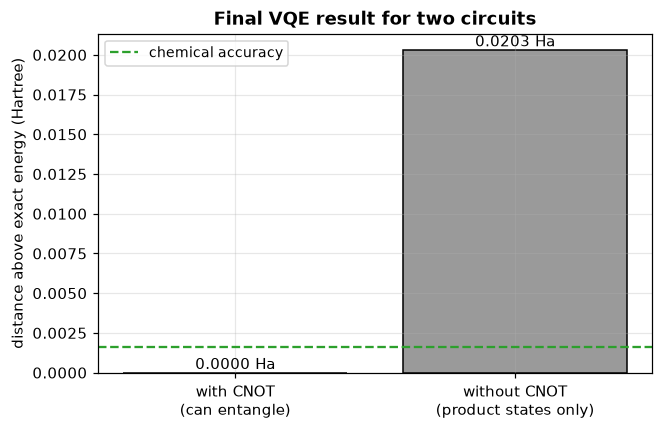

In [ ]:
product_ansatz = QuantumCircuit(2)
product_ansatz.ry(params[0], 0)
product_ansatz.ry(params[1], 1)
product_ansatz.ry(params[2], 0)
product_ansatz.ry(params[3], 1)

result_product = minimize(lambda v: energy(product_ansatz, v), start, method="COBYLA", options={"maxiter": 200})
gaps = [result_h2.fun - E0, result_product.fun - E0]

print(f"With CNOT    : {result_h2.fun:.4f} Ha   distance above exact {gaps[0]:.4f} Ha")
print(f"Without CNOT : {result_product.fun:.4f} Ha   distance above exact {gaps[1]:.4f} Ha  ({gaps[1] / 1.6e-3:.0f} × chemical accuracy)")

plt.figure(figsize=(6.5, 4))
bars = plt.bar(["with CNOT\n(can entangle)", "without CNOT\n(product states only)"], gaps, color=[BLUE, GREY], edgecolor="black")
plt.bar_label(bars, labels=[f"{g:.4f} Ha" for g in gaps])
plt.axhline(1.6e-3, color=GREEN, ls="--", label="chemical accuracy")
plt.ylabel("distance above exact energy (Hartree)")
plt.title("Final VQE result for two circuits")
plt.legend(fontsize=9)
plt.show()

Without the CNOT, VQE stops at $-1.8370$ Ha, the Hartree–Fock energy, about 13 times outside chemical accuracy. The ground state is entangled, and a circuit that cannot entangle can never prepare it. **The ansatz decides which states, and therefore which energies, VQE can reach.**

## 9. What this does and does not show

**What it shows**

- The full VQA loop works: the quantum computer prepares and measures the trial state, and the classical optimiser chooses the parameters.
- VQE found the exact ground-state energy and ground state of H₂.
- The ansatz has to be able to reach the answer, which here meant allowing entanglement.

**Its limits**

- Everything ran on a simulator, without hardware errors.
- H₂ is tiny, so there is no speed-up here.
- Bigger molecules need many more Pauli strings, shots and parameters.
- Classical optimisers can get stuck in false minima or in large flat regions, called **barren plateaus**.

Moving a step onto a quantum computer changes what the cost of the calculation depends on. It does not automatically make it faster.

### Key equations

| Idea | Equation |
|---|---|
| Trial state | $\lvert\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)\lvert 0\rangle$ |
| Expectation value | $\langle O\rangle = \langle\psi\rvert O\lvert\psi\rangle = \sum_j c_j\langle P_j\rangle$ |
| Cost function | $C(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)\rvert O\lvert\psi(\boldsymbol\theta)\rangle$ |
| Goal | $\boldsymbol\theta^* = \arg\min_{\boldsymbol\theta} C(\boldsymbol\theta)$ |
| Eigenvalues | $H\lvert\psi_k\rangle = E_k\lvert\psi_k\rangle$ |
| Variational principle | $\langle\psi(\boldsymbol\theta)\rvert H\lvert\psi(\boldsymbol\theta)\rangle \ge E_0$ |
